# 30 · Author history in depth, variance components, brand totals, anomalies, views per like (E70-E75)

Over-performance = true − predicted log10 views of the out-of-fold final model (5 brand folds per platform). Outputs carry statistics only, never author names or URLs.

In [1]:
import sys, json, warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw" / "reach_samples_students.csv").exists())
sys.path.insert(0, str(ROOT / "src"))
pd.set_option("display.width", 250, "display.max_columns", 30)
import extra_models as em, eda_utils as eu, history as H, account_clusters as ac, author_more as am, more_models as mm, posting_time_text as ptt

In [2]:
f, meta = em.load(ROOT); raw_all = eu.load(ROOT); raw = raw_all.loc[f.index]
labels = pd.read_csv(ROOT / "data" / "processed" / "mention_labels.csv", dtype={"mention_id": str}).set_index("mention_id").type
lab = pd.Series(labels.reindex(raw.mention_id.astype(str)).values, index=raw.index)
kind = ac.account_kind(raw); copy_flag = mm.copies(ROOT)[2].is_copy.loc[raw.index]
pred = ac.oof(f, meta); d = am.frame(raw, meta, pred); h = am.history_features(d)
print(h.hn.notna().groupby(d.platform).sum().to_dict())

{'tiktok': 63, 'twitter': 112, 'youtube': 379}


## E70 · Author history in depth
Corrections on posts that have an earlier non-repeat post by the same author; parameters chosen on other brand folds.

In [3]:
P70 = am.history_variants(d, h); S70 = H.summarise(P70); display(S70.pivot(index="model", columns="platform", values="MAE")[am.PLATS].round(3))
G70 = pd.DataFrame([{"platform": p, "model": k, **dict(zip(["gain", "CI low", "CI high"], H.gain_ci(P70, p, "final model", k)))} for p in am.PLATS for k in ['+ a × mean of earlier', '+ a × last earlier post', '+ sum / (n + k), shrunk by count']]); G70.round(3)

platform,tiktok,youtube,twitter
model,,,
+ a × last earlier post,0.273,0.352,0.461
+ a × mean of earlier,0.262,0.347,0.428
"+ sum / (n + k), shrunk by count",0.258,0.347,0.426
final model,0.373,0.495,0.528


,platform,model,gain,CI low,CI high
0,tiktok,+ a × mean of earlier,0.111,0.046,0.187
1,tiktok,+ a × last earlier post,0.101,0.031,0.169
2,tiktok,"+ sum / (n + k), shrunk by count",0.116,0.049,0.194
3,youtube,+ a × mean of earlier,0.149,0.095,0.206
4,youtube,+ a × last earlier post,0.144,0.094,0.202
5,youtube,"+ sum / (n + k), shrunk by count",0.149,0.097,0.211
6,twitter,+ a × mean of earlier,0.099,0.028,0.162
7,twitter,+ a × last earlier post,0.067,-0.004,0.124
8,twitter,"+ sum / (n + k), shrunk by count",0.102,0.033,0.164


In [4]:
B70 = P70.groupby(["platform", "earlier", "model"]).apply(lambda q: pd.Series({"posts": len(q), "MAE": float((q.y - q.pred).abs().mean())})).reset_index()
B70 = B70[B70.model.isin(["final model", "+ sum / (n + k), shrunk by count"])].pivot_table(index=["platform", "earlier"], columns="model", values=["posts", "MAE"]).round(3); B70

MAE                                        posts            
model            + sum / (n + k), shrunk by count final model + sum / (n + k), shrunk by count final model
platform earlier                                                                                          
tiktok   1                                  0.268       0.394                             50.0        50.0
         2                                  0.214       0.315                             11.0        11.0
         3+                                 0.258       0.179                              2.0         2.0
twitter  1                                  0.373       0.521                             63.0        63.0
         2                                  0.407       0.465                             14.0        14.0
         3+                                 0.527       0.564                             35.0        35.0
youtube  1                                  0.353       0.487                            239.0       239.0
         2                                  0.307       0.488                             65.0        65.0
         3+                                 0.361       0.530                             75.0        75.0

At posting time (no reactions): the E43 posting-time model (followers + posting-time columns) and the same with the author's earlier over-performance against that model.

In [5]:
groups, pmeta, _ = ptt.data(ROOT, ROOT / "data" / "processed" / "embeddings_e5_cache.pkl"); assert set(pmeta.index) == set(f.index)
pt = am.posting_time_oof(groups, pmeta.loc[f.index], f); d_pt = am.frame(raw, meta, pt); h_pt = am.history_features(d_pt)
P70t = am.history_variants(d_pt, h_pt); P70t["model"] = P70t.model.str.replace("final model", "posting-time model")
S70t = H.summarise(P70t); display(S70t.pivot(index="model", columns="platform", values="MAE")[am.PLATS].round(3))
G70t = pd.DataFrame([{"platform": p, "model": k, **dict(zip(["gain", "CI low", "CI high"], H.gain_ci(P70t, p, "posting-time model", k)))} for p in am.PLATS for k in ['+ a × mean of earlier', '+ sum / (n + k), shrunk by count']]); G70t.round(3)

platform,tiktok,youtube,twitter
model,,,
+ a × last earlier post,0.552,0.513,0.423
+ a × mean of earlier,0.493,0.504,0.434
"+ sum / (n + k), shrunk by count",0.486,0.491,0.433
posting-time model,0.655,0.632,0.582


,platform,model,gain,CI low,CI high
0,tiktok,+ a × mean of earlier,0.162,0.034,0.300
1,tiktok,"+ sum / (n + k), shrunk by count",0.169,0.045,0.305
2,youtube,+ a × mean of earlier,0.128,0.061,0.193
3,youtube,"+ sum / (n + k), shrunk by count",0.141,0.071,0.214
4,twitter,+ a × mean of earlier,0.148,0.090,0.204
5,twitter,"+ sum / (n + k), shrunk by count",0.148,0.090,0.204


## E71 · Can the author's level be predicted without history?

In [6]:
A71 = am.author_level(d, kind); A71.round(3)

,platform,authors,Spearman (features),R² (features),split-half Spearman (history),sd of author level
0,tiktok,61,-0.053,-0.282,0.697,0.438
1,youtube,255,-0.028,-0.214,0.705,0.592
2,twitter,83,-0.116,-0.405,0.678,0.556


## E72 · Variance components
Share of the variance shared by posts of the same author, and by posts of the same brand from other authors. For the final model's error and for raw log views.

In [7]:
V72 = pd.concat([am.variance_components(d, "r"), am.variance_components(d, "y")], ignore_index=True); V72.round(3)

,platform,quantity,same-author pairs,share shared by an author,author low,author high,same-brand other-author pairs,share shared by a brand,brand low,brand high
0,tiktok,r,103,0.740,0.611,0.858,15162,0.055,0.020,0.096
1,youtube,r,757,0.631,0.564,0.756,14177,0.028,-0.005,0.056
2,twitter,r,686,0.119,0.084,0.442,7792,0.075,0.036,0.106
3,tiktok,y,103,0.767,0.657,0.876,15162,0.059,0.026,0.102
4,youtube,y,757,0.799,0.746,0.861,14177,0.086,0.052,0.125
5,twitter,y,686,0.464,0.429,0.771,7792,0.074,0.026,0.110


## E73 · Brand totals
What a client sees: the summed views of a brand (and of a brand in one month). Predicted total = sum of 10^prediction × smearing factor from the other folds.

In [8]:
T73 = am.brand_totals(raw, meta, pred); T73.round(3).T

,0,1,2,3,4,5
platform,tiktok,tiktok,youtube,youtube,twitter,twitter
unit,brand,brand-month,brand,brand-month,brand,brand-month
units,238,392,213,324,189,232
median posts,10.0,5.0,10.0,5.0,8.0,5.0
per-post MAE,0.273,0.273,0.456,0.456,0.466,0.466
MAE of total (calibrated),0.227,0.23,0.311,0.305,0.317,0.345
bias of total (calibrated),-0.021,-0.019,-0.083,-0.05,-0.028,-0.039
MAE of total (sum of medians),0.232,0.234,0.338,0.332,0.364,0.386
bias of total (sum of medians),-0.099,-0.097,-0.242,-0.209,-0.246,-0.257
share within ×2,0.727,0.717,0.653,0.633,0.556,0.496


## E74 · Anomalies: ×10 above or below the prediction

In [9]:
N74 = am.anomalies(d, kind, lab, copy_flag); display(N74.round(3)); Q74 = am.anomaly_persistence(d, h); Q74.round(3)

,platform,group,posts,share of posts,promo,spam,organic,zero reactions,copied text,brand or brand-named account,news / media,median followers,median likes,median true views,author with >= 2 posts
0,tiktok,rest,2430,0.976,0.335,0.131,0.479,0.031,0.010,0.041,0.012,1530.496,33.0,724.999,0.055
1,tiktok,×10 above,32,0.013,0.594,0.125,0.281,0.031,0.094,0.094,0.000,12909.389,31.0,13840.251,0.156
2,tiktok,×10 below,29,0.012,0.379,0.310,0.207,0.483,0.034,0.000,0.000,374.000,1.0,5.000,0.069
3,youtube,rest,2218,0.909,0.422,0.146,0.306,0.239,0.009,0.035,0.069,29800.000,10.0,410.000,0.267
4,youtube,×10 above,139,0.057,0.453,0.223,0.259,0.475,0.050,0.094,0.058,26700.000,0.0,7306.000,0.252
5,youtube,×10 below,84,0.034,0.440,0.190,0.226,0.821,0.060,0.036,0.095,18500.000,0.0,6.481,0.333
6,twitter,rest,1624,0.901,0.189,0.111,0.691,0.541,0.033,0.004,0.017,542.992,0.0,26.000,0.119
7,twitter,×10 above,109,0.060,0.147,0.202,0.642,0.615,0.083,0.009,0.037,246.317,0.0,375.000,0.229
8,twitter,×10 below,70,0.039,0.157,0.129,0.714,0.657,0.057,0.029,0.000,757.036,0.0,1.000,0.129


,platform,posts,earlier mean >= 0.5,P(×10 above | high history),P(×10 above | other),"P(×10 above), all posts"
0,tiktok,63,8,0.125,0.018,0.013
1,youtube,379,78,0.192,0.013,0.057
2,twitter,112,19,0.316,0.054,0.060


## E75 · Views per like implied by the final model
Brand24's rule: 700 views per reaction on X (300 above 10 reactions).

In [10]:
V75 = am.views_per_like(f, meta, raw); V75.round(2)

,platform,followers,likes,posts,median predicted views,median true views,predicted views per like,true views per like,elasticity (doubling reactions)
0,tiktok,100k-1M,10-99,32,1477.56,1621.0,34.23,36.52,0.62
1,tiktok,100k-1M,100-999,51,8062.14,8678.0,25.47,28.72,0.58
2,tiktok,100k-1M,1000+,48,79280.44,84417.0,15.91,16.67,0.52
3,tiktok,10k-100k,1-9,54,314.37,355.5,63.70,65.38,0.36
4,tiktok,10k-100k,10-99,182,867.23,950.5,26.42,24.87,0.60
5,tiktok,10k-100k,100-999,138,5803.14,5873.5,22.50,19.81,0.70
6,tiktok,10k-100k,1000+,61,53716.24,59623.0,14.86,16.46,0.57
7,tiktok,1k-10k,1-9,168,223.26,225.0,53.27,52.47,0.40
8,tiktok,1k-10k,10-99,422,592.34,626.0,19.88,20.47,0.58
9,tiktok,1k-10k,100-999,154,3689.51,4291.5,18.44,20.49,0.71


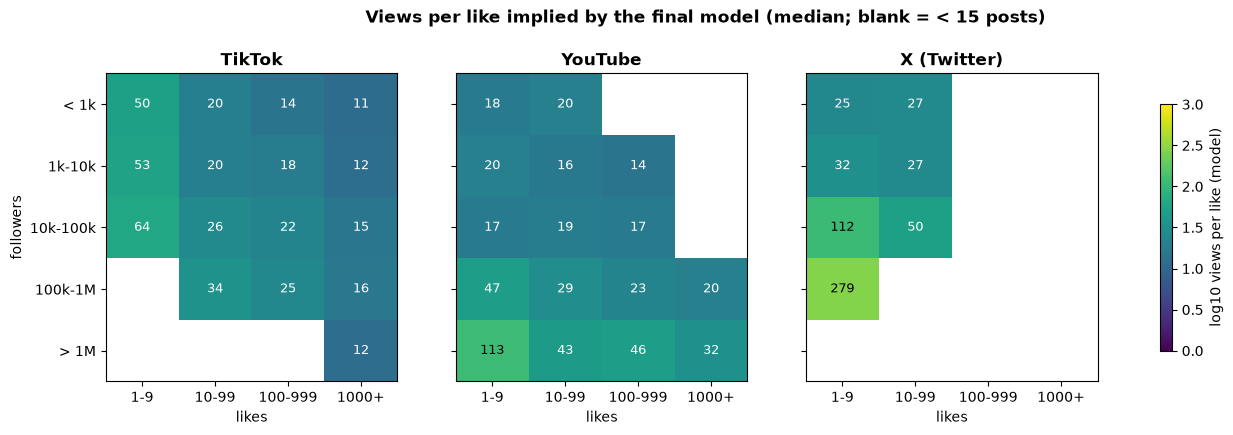

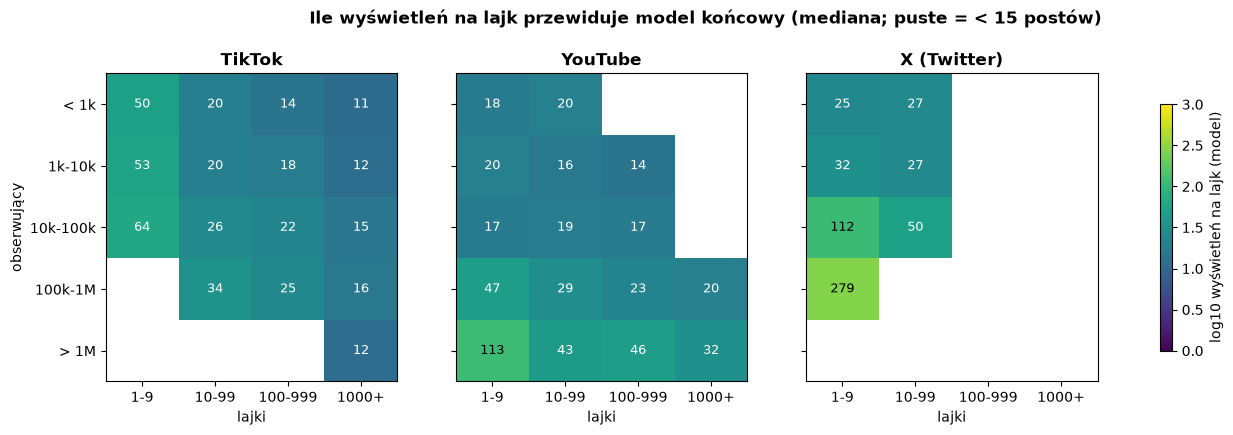

In [11]:
am.plot_vpl(V75, ROOT / "figures" / "views_per_like_en.png", "en"); am.plot_vpl(V75, ROOT / "figures" / "views_per_like_pl.png", "pl")

## Takeaways
See `docs/en/experiments.md` (E70-E75). Numbers: `data/processed/author_more_numbers.json`.

In [12]:
json.dump({"history_models": S70.to_dict("records"), "history_gains": G70.to_dict("records"), "history_by_count": B70.reset_index().to_dict("records") if False else json.loads(B70.to_json(orient="split")),
           "posting_time_models": S70t.to_dict("records"), "posting_time_gains": G70t.to_dict("records"), "author_level": A71.to_dict("records"), "variance": V72.to_dict("records"),
           "brand_totals": T73.to_dict("records"), "anomalies": N74.to_dict("records"), "anomaly_persistence": Q74.to_dict("records"), "views_per_like": V75.to_dict("records")},
          open(ROOT / "data" / "processed" / "author_more_numbers.json", "w"), indent=1, default=float)